In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

In [5]:
prefix = '/mnt/staging/' # or 
mouse='cm229'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
raw_full_video_root = step_3_root+mouse+'/dc_full_front/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'
figure_config_root = str(PREPARES / "config") + "/"

fetch_path_licking = str(PREPARES / "epochs-licking") + "/"
fetch_path_CLS = str(PREPARES / "CLS") + "/"

In [6]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]

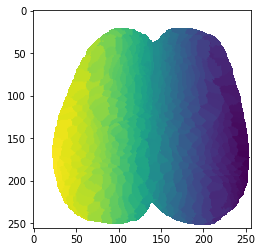

In [7]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [8]:
all_bdps_list_S1 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RT','LFP', 'LHP',  'LW', 'LM', 'LN','LT']
all_bdps_list_M2 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RV','LFP', 'LHP',  'LW', 'LM', 'LN','LV']
all_bdps_list_M1 = [ 'RFP', 'RHP', 'LFP', 'LHP']
all_bdps_extra = ['RALM','LALM', 'RV', 'LV','RRSP','LRSP','RFP_M1_extra','LFP_M1_extra', 
                 'RholeMOp','LholeMOp',
                 'Rposterior','Lposterior'
                 ]
all_bdps_S1 = [bdp+'_S1' for bdp in all_bdps_list_S1]
all_bdps_M2 = [bdp+'_M2' for bdp in all_bdps_list_M2]
all_bdps_M1 = [bdp+'_M1' for bdp in all_bdps_list_M1]

all_bdps = all_bdps_extra + all_bdps_M2 + all_bdps_S1 + all_bdps_M1


In [9]:
all_bdps_w_order = [ 'RFP', 'RHP',  'RW', 'RM','LFP', 'LHP',  'LW', 'LM']
extra_bdp_dict = {'ALM-M2':0, 'RV-S1M1':1, 'LV-S1M1':2,'RSP-S1M1':3,
                  'RFP_M1_extra-S1M1':4,'LFP_M1_extra-S1M1':5}
extra_bdp_list = extra_bdp_dict


# load licking data

In [10]:
mice = ['cm229']

In [11]:
all_gathered = ['M_jrgeco',
               'M_day_label','M_ind','M_licking',
                'M_is_groom','M_face_pc','M_body_pc',
                'M_LFP_vel','M_RFP_vel','M_rotf']
dict_collection_mice = {}
dict_T_PRE_mice = {}
dict_ds_factor_mice = {}
dict_fs_mice = {}
dict_step_1_root_mice = {}
dict_IDX_sorted_mice = {}
dict_M2_ind_mice = {}
dict_S1_ind_mice = {}
dict_node_coords_mice = {}
for mouse_id in mice:
    dict_collection_mice[mouse_id] = {}
    f = scipy.io.loadmat(fetch_path_licking+mouse_id+'_lick-during-run.mat')
    for key in all_gathered:
        dict_collection_mice[mouse_id][key]=np.squeeze(f[key])
    if mouse_id == 'cm229':
        dict_T_PRE_mice[mouse_id]=90
        dict_ds_factor_mice[mouse_id] = 4
        dict_fs_mice[mouse_id] = 15
        dict_step_1_root_mice[mouse_id]=step_1_root
    elif mouse_id in ['cm241','cm242']:
        dict_T_PRE_mice[mouse_id]=60
        dict_ds_factor_mice[mouse_id] = 3
        dict_fs_mice[mouse_id] = 20
        dict_step_1_root_mice[mouse_id]=step_1_root
    
    with h5py.File(dict_step_1_root_mice[mouse_id].replace('step_1','step_0')+mouse+'/idx_sorted_500_{}.mat'.format(mouse_id),'r') as f_idx:
        IDX_sorted = np.array(f_idx['IDX_sorted']).T
        IDX_sorted = IDX_sorted.astype(float)
        IDX_sorted[IDX_sorted==0]='nan'
        props = regionprops(IDX_sorted.astype(int))
        node_coords = [props[i].centroid for i in range(len(props))]
        node_coords = np.asarray(node_coords, dtype=np.float32)
    
        dict_node_coords_mice[mouse_id] = node_coords
        dict_IDX_sorted_mice[mouse_id] = IDX_sorted
        
    M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse_id)
    sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse_id)
    if mouse_id == 'cm229':
        sensory_ind['LW']=37  
        sensory_ind['RM']= 475 
        sensory_ind['LM'] = 31
    else:
        sensory_ind['RM']= sensory_ind['mouth']
        M2_ind['RM']= M2_ind['mouth']
        if mouse_id == 'cm242':
            sensory_ind['RM'] = 462
            temp = sensory_ind['RW'] 
            sensory_ind['RW'] = sensory_ind['LW']
            sensory_ind['LW'] = temp
    dict_M2_ind_mice[mouse_id] = M2_ind
    dict_S1_ind_mice[mouse_id] = sensory_ind

In [12]:
dict_full_jrgeco_mice = {}
T_total = 100
for mouse_id in mice:
    # mouse config
    M_day_label_here = dict_collection_mice[mouse_id]['M_day_label']
    M_ind_here = dict_collection_mice[mouse_id]['M_ind']
    ds_factor_here = dict_ds_factor_mice[mouse_id]
    step_1_root_here = dict_step_1_root_mice[mouse_id]
    T_PRE_here = dict_T_PRE_mice[mouse_id]
    dict_full_jrgeco_mice[mouse_id] = np.empty((256,256,T_total,0))
    
    # fetch full data
    for i_session, session_id in enumerate(M_day_label_here):
        session_id = session_id.split(' ')[0] # eliminate empty spaces
        day = session_id.split(mouse_id+'_')[1].split('_')[0]
        run_id = session_id.split(mouse_id+'_')[1].split('_')[1]

        f3 = list(set(glob.glob(step_1_root_here+mouse_id+"/"+day+"/*"+run_id+"*.mat")))[0]
        ind = int(M_ind_here[i_session]/ds_factor_here)
        with h5py.File(f3,'r') as f_H: 
            m = f_H['m']
            C = np.array(f_H['C']['jrgeco'])
            S = np.array(f_H['S']['jrgeco'])[ind-40:ind+60,:]
            # cut [-60,60] frames slice
            mask = np.array(f_H['mask'])
            # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
            nanidx = np.squeeze(m['nanidx'])==1
            CS = np.dot(S,C).transpose()
            jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
            jrgeco[:] = np.nan
            jrgeco[nanidx==True,:] = CS
            jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))
            
            dict_full_jrgeco_mice[mouse_id] = np.append(dict_full_jrgeco_mice[mouse_id],jrgeco[:,:,:,np.newaxis],axis=3)


In [13]:
T_PRE_all_mice = 40

dict_full_jrgeco_dbsl_mice = {}
dict_H_dbsl_mice = {}
# new baseline for full jrgeco data
for mouse_id in mice:
    if mouse_id in ['cm242']:
        baseline_range = range(T_PRE_all_mice-17,T_PRE_all_mice-7)
    else:
        baseline_range = range(T_PRE_all_mice-30,T_PRE_all_mice-7)
    dff_here = dict_full_jrgeco_mice[mouse_id]
    # dict_full_jrgeco_dbsl_mice[mouse_id] = np.divide(dff_here+1,np.mean(dff_here[:,:,baseline_range,:],2)[:,:,np.newaxis,:]+1)-1
    dict_full_jrgeco_dbsl_mice[mouse_id] = dff_here - np.mean(dff_here[:,:,baseline_range,:],2)[:,:,np.newaxis,:] 
    dict_H_dbsl_mice[mouse_id] = getH_4D(dict_full_jrgeco_dbsl_mice[mouse_id],dict_IDX_sorted_mice[mouse_id])
    

In [14]:
T_PRE_all_mice

40

In [15]:
dict_full_jrgeco_mice['cm229'].shape

(256, 256, 100, 18)

# fit NNLS

In [16]:
full_jrgeco = dict_full_jrgeco_mice['cm229']

In [17]:
full_jrgeco = full_jrgeco - np.mean(full_jrgeco[:,:,16:35,:],axis=2)[:,:,np.newaxis,:]

In [18]:
H_dbsl = getH_4D(full_jrgeco,IDX_sorted)

In [19]:
concat_H = H_dbsl.transpose((0,2,1)).reshape((500,-1))
concat_full_jrgeco = full_jrgeco.transpose((0,1,3,2)).reshape((256,256,-1))

In [20]:
with h5py.File(figure_config_root+'mask_midline_v2_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
ss_here = full_jrgeco.shape
mask_midline_array = np.repeat(np.repeat(mask_midline[:,:,np.newaxis],
                     repeats=ss_here[2],axis=2)[:,:,:,np.newaxis],repeats=ss_here[3],axis=3)
full_jrgeco = np.multiply(full_jrgeco,mask_midline_array)


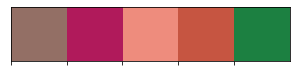

In [21]:
def hex_to_rgb(hex_value):
  h = hex_value.lstrip('#')
  return tuple(int(h[i:i + 2], 16) / 255.0 for i in (0, 2, 4))
# new_palette = ['#FFAE4E','#2A7377','#7B4EA1','#BAB2AC','#2C5B78']
new_palette = [palatte_dict['ALM'],palatte_dict['RV'],palatte_dict['LV'],
               palatte_dict['RSP'],palatte_dict['nose']]
rgb_colors = list(map(hex_to_rgb, new_palette))

sns.palplot(rgb_colors)

In [22]:
extra_bdp_color_dict = {
    'ALM-M2':palatte_dict['ALM'], 'RV-S1M1':palatte_dict['nose'],
                        'LV-S1M1':palatte_dict['nose'],'RSP-S1M1':palatte_dict['RSP'],
                        
                        'RALM':palatte_dict['ALM'],'LALM':palatte_dict['ALM'],
                        'RRSP':palatte_dict['RSP'],'LRSP':palatte_dict['RSP'],
                        
                  'RFP_M1_extra':palatte_dict['LFP'],
                        'LFP_M1_extra':palatte_dict['LFP'],
                       'median':palatte_dict['LV']}

In [23]:
mouse_id= 'cm229'
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')
M2_ind_here = dict_M2_ind_mice[mouse_id]
sensory_ind_here = dict_S1_ind_mice[mouse_id]
ds_factor_here = dict_ds_factor_mice[mouse_id]
list_choice_M2 = ['RFP','RM','RW','RHP']
list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse_id]
node_coords_here = dict_node_coords_mice[mouse_id]
fs_here = 15
collection_here = dict_collection_mice[mouse_id]
list_select_behavior_2show = ['M_licking','M_LFP_vel','M_RFP_vel', 'M_rotf']
palatte_behavior_dict = load_pickle(figure_config_root+'palatte_behavior_dict')

# IMPORTANT: 
jrgeco2plot_M2 = {};node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    small_roi_tcs = np.nanmean(np.nanmean(
dict_full_jrgeco_dbsl_mice[mouse_id][x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs

In [24]:
extra_bdp_color_dict = {
    'ALM-M2':palatte_dict['ALM'], 'RV-S1M1':palatte_dict['nose'],
                        'LV-S1M1':palatte_dict['nose'],'RSP-S1M1':palatte_dict['RSP'],
                        
                        'RALM':palatte_dict['ALM'],'LALM':palatte_dict['ALM'],
                        'RRSP':palatte_dict['RSP'],'LRSP':palatte_dict['RSP'],
                        
                  'RFP_M1_extra':palatte_dict['LFP'],
                        'LFP_M1_extra':palatte_dict['LFP'],
                       'median':palatte_dict['LV']}

In [25]:
save_dict = load_pickle(fetch_path_CLS+'M2S1M1_NNLS_spatial_'+mouse)
all_bdps_w_order = save_dict['all_bdps_w_order']
full_M = save_dict['full_M']
# mask_M2 = save_dict['mask_M2']
# concat_jrgeco = load_pickle(load_path+'concat_jrgeco')

mask = np.mean(np.mean(full_jrgeco,-1),-1)>-1
mask = mask.astype(float)
mask[mask==0]=np.nan
mask_reshape = mask.reshape((256*256))

W_S1M2M1 = full_M[mask_reshape==1,:]

# W_masked_S1M2M1 = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked_S1M2M1[:]=np.nan
# W_masked_S1M2M1[mask_reshape==1,:] = W_S1M2M1
# W_masked_S1M2M1 = W_masked_S1M2M1.reshape((256,256,-1))

# add M2 ones
W_S1M2M1_M2 = []
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    W_S1M2M1_M2.append(W_S1M2M1[:,ind_in_list])
W_S1M2M1_M2_sum = np.clip(np.sum(np.stack(W_S1M2M1_M2,0),0), 0, 1)
W_S1M2M1 = np.append(W_S1M2M1,W_S1M2M1_M2_sum[:,np.newaxis],axis=1)
# add cortical ones
W_S1M2M1 = np.append(W_S1M2M1,np.ones((len(W_S1M2M1_M2_sum),1)),axis=1)

W_masked = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked[:]=np.nan
W_masked[mask_reshape==1,:] = W_S1M2M1
W_masked = W_masked.reshape((256,256,-1))


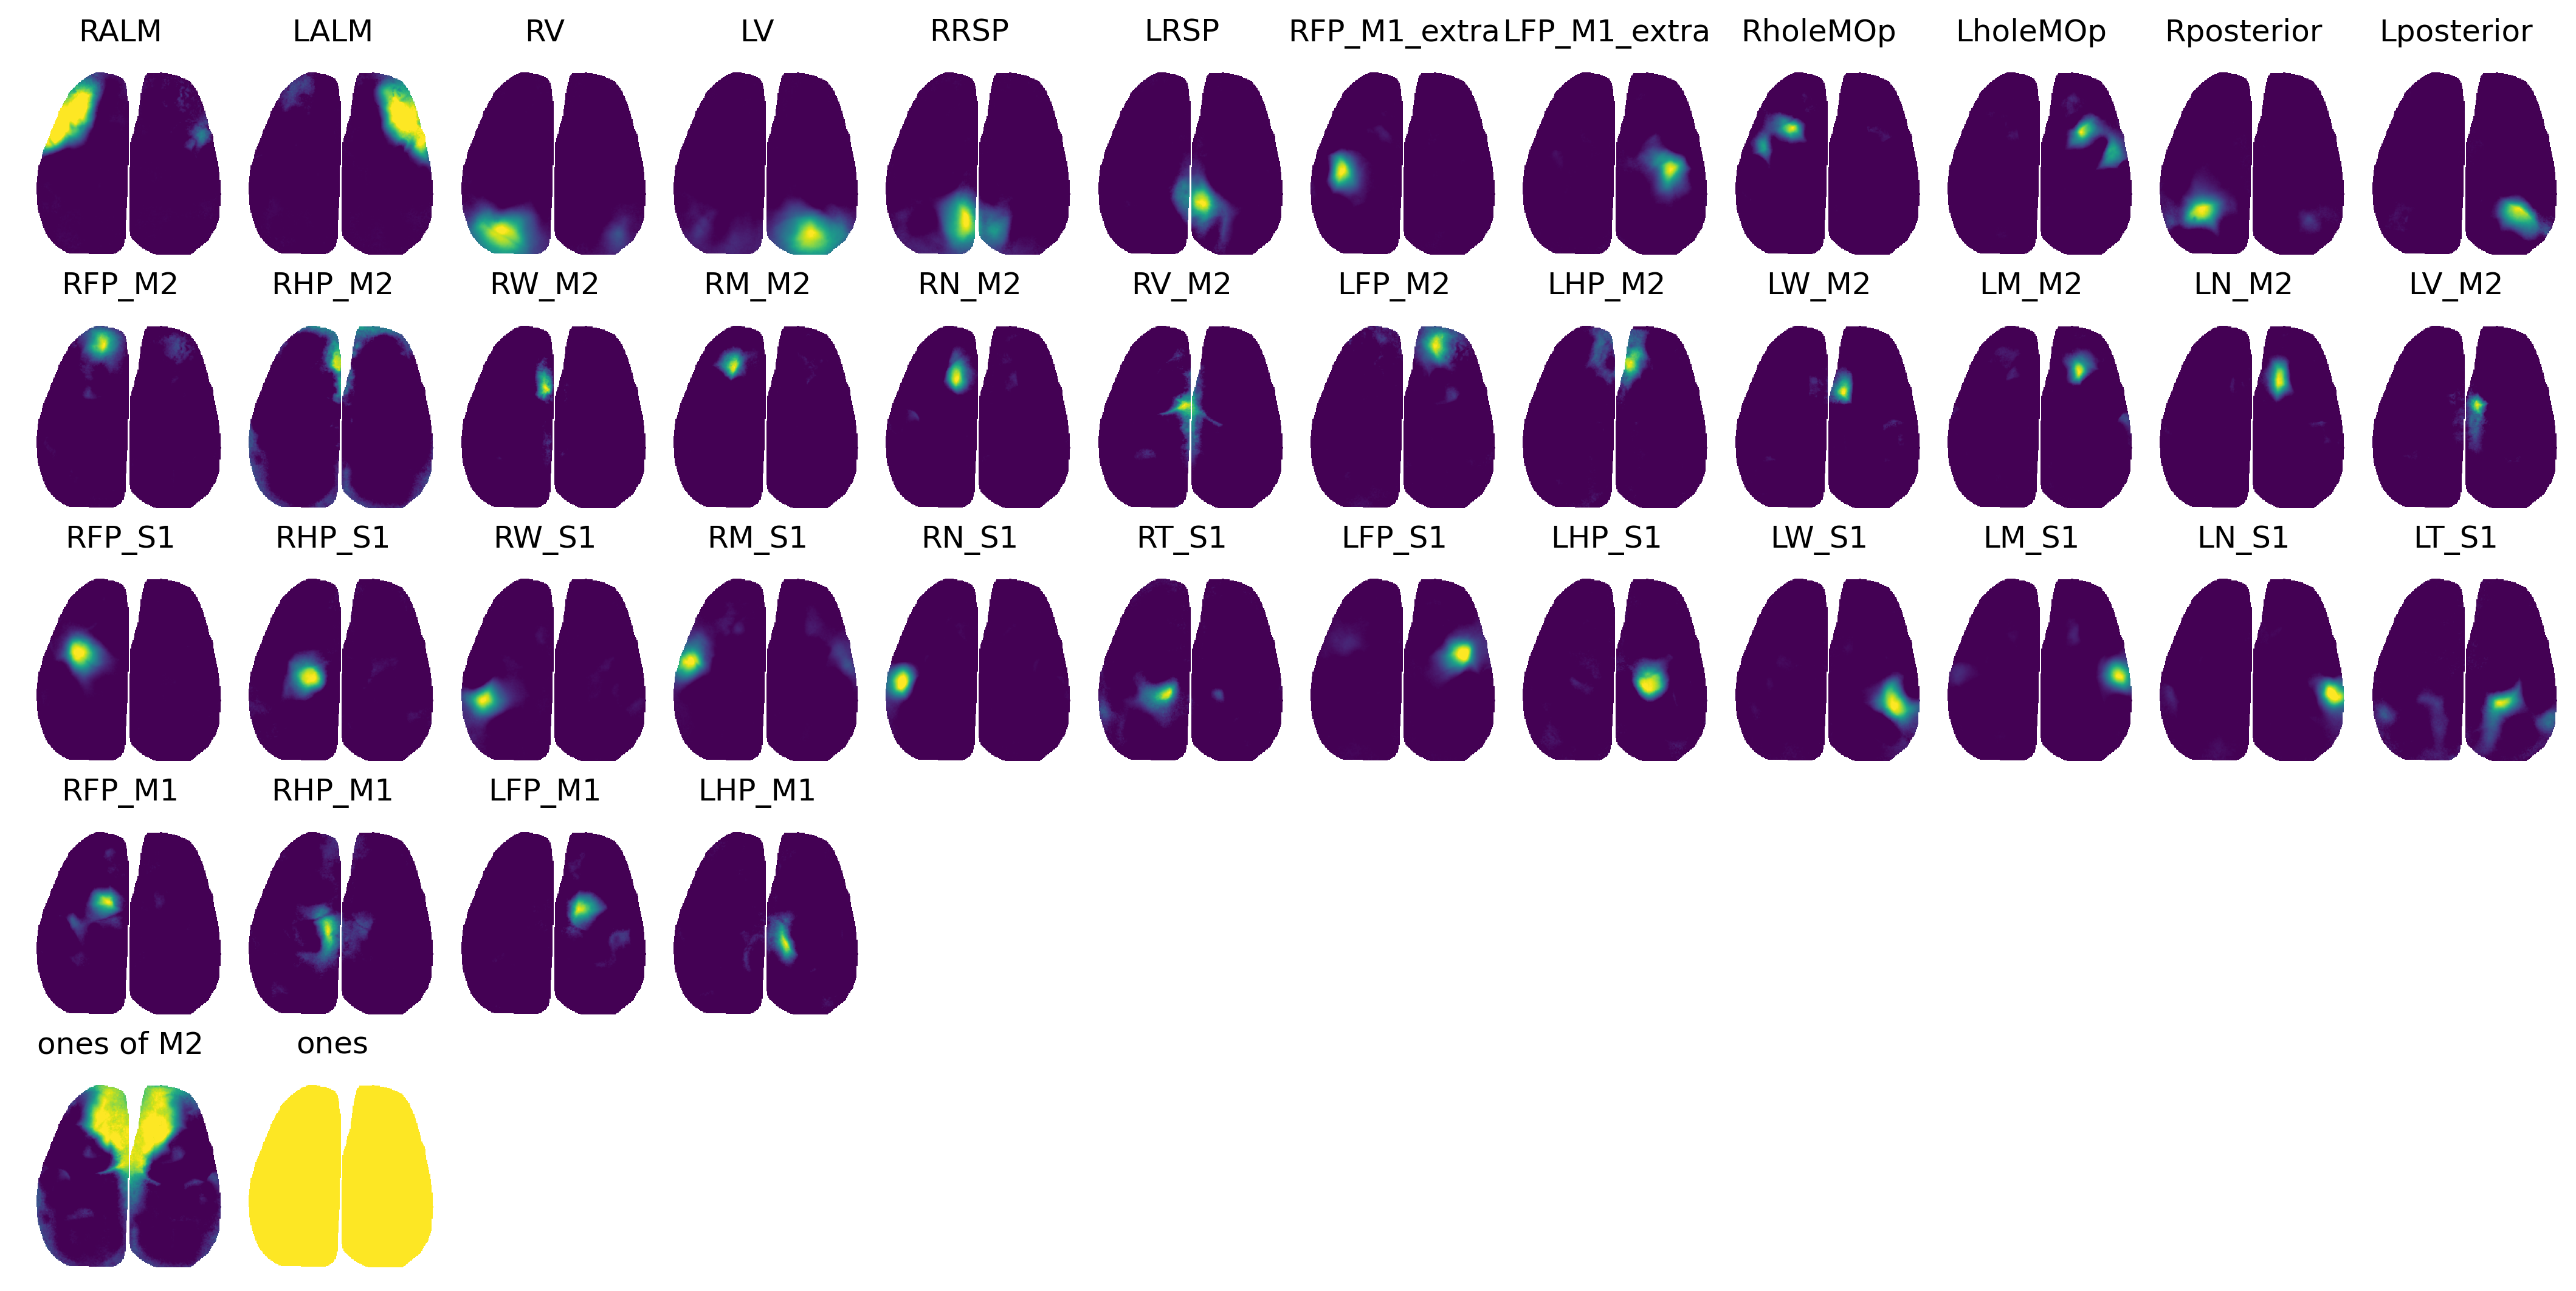

In [26]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+12:y_offset+17,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+18:y_offset+23,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)+2):
    exec("ax{} = fig.add_subplot(gs[y_offset+24:y_offset+29,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
##########################################
##########################################
for i_key,key in enumerate(all_bdps_extra):
    ind_in_list = all_bdps.index(key)
    W_masked_2show = W_masked[:,:,ind_in_list]        
    exec("ax{}.imshow(W_masked_2show,vmin=0,vmax=1)".format(i_key))
    exec("ax{}.set_title(key)".format(i_key))
    # plt.axis('off')
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_S1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_M1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))

# plot median
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)
exec("ax{}.imshow(W_masked[:,:,-2],vmin=0,vmax=1)".format(i_entry))
exec("ax{}.set_title('ones of M2')".format(i_entry))
 
# plot 1
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)+1
exec("ax{}.imshow(W_masked[:,:,-1],vmin=0,vmax=0.1)".format(i_entry))
exec("ax{}.set_title('ones')".format(i_entry))

for i_ax in range(50):
    try:
        exec("ax{}.axis('off')".format(i_ax))
    except:
        continue

In [27]:
mouse_id = mouse
   
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse_id)
sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse_id)

extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse_id)
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse_id)

# sensory_ind['RV']=extra_extra_ind['RV']
# sensory_ind['LV']=extra_extra_ind['LV']
sensory_ind['LV']=106
sensory_ind['RV']=415

M1_ind_from_coherence = load_pickle(fetch_path_M1+'M1_ind_'+mouse)

sensory_ind['LW']=54
sensory_ind['RW']=464
sensory_ind['RRSP']= 310 # cm229
sensory_ind['LRSP']= 211 # cm229
sensory_ind['LALM']=extra_ind['ALM']
sensory_ind['RALM']=447
sensory_ind['RFP_M1_extra']=440 # cm229
sensory_ind['LFP_M1_extra']=79 # cm229
sensory_ind['RholeMOp']=381 # cm229
sensory_ind['LholeMOp']=119 # cm229
sensory_ind['RT']=sensory_ind['tail'] # cm229
sensory_ind['LT']=139
sensory_ind['Rposterior']=418 # cm229
sensory_ind['Lposterior']=80 # cm229

In [28]:
TCs_matrix = np.empty((0,concat_H.shape[1]))

for i_key,key in enumerate(all_bdps_extra):
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[sensory_ind[key],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M2):
    bdp = key.split('_M2')[0]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    small_roi_tcs = np.nanmean(np.nanmean(
concat_full_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    TCs_matrix = np.append(TCs_matrix,
                           small_roi_tcs[np.newaxis,:],
                           axis=0)

for i_key,key in enumerate(all_bdps_S1):
    bdp = key.split('_S1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[sensory_ind[bdp],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M1):
    bdp = key.split('_M1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           concat_H[M1_ind_from_coherence[bdp],np.newaxis,:],
                           axis=0)
    

In [29]:
# append MEAN tc 
index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
TCs_matrix=np.append(TCs_matrix,np.mean(TCs_matrix[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
# append 1 tc 
TCs_matrix = np.append(TCs_matrix,np.ones((1,TCs_matrix.shape[1])),axis=0)

# solve H with known W

In [30]:
from scipy.optimize import minimize
from scipy.sparse import csr_matrix
def nnls_optimization_with_constraints(A, b,x_init,constraints):
    """
    Solves the Non-Negative Least Squares (NNLS) problem using constrained optimization.

    Parameters:
    A (numpy.ndarray or scipy.sparse.csr_matrix): The input matrix.
    b (numpy.ndarray): The input vector.

    Returns:
    numpy.ndarray: The solution vector x.
    """
    # Check if A is sparse and convert to csr_matrix if it is not
    if not isinstance(A, csr_matrix):
        A = csr_matrix(A)

    # Objective function: 0.5 * ||Ax - b||^2
    def objective(x):
        residual = A.dot(x) - b
        return 0.5 * np.linalg.norm(residual)**2

    # Gradient of the objective function
    def objective_jac(x):
        return A.T.dot(A.dot(x) - b)

    # Initial guess (zeros)
    x0 = x_init #np.zeros(A.shape[1])
    # x0 = np.zeros(A.shape[1])

    
    result = minimize(objective, x0, method='SLSQP',constraints=constraints,jac=objective_jac, options={'disp': False})

    return result.x

index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
  
def return_constraints(H_ROI,median_here,index_M2s,k):
    # Define the constraints
    constraints = []
    for i_M2 in index_M2s:
        constraints.append({
            'type': 'eq',
            'fun': lambda x, i_M2=i_M2: x[i_M2] - (H_ROI[i_M2] - x[-2])
        })
    # constraints.append({'type': 'eq', 'fun': lambda x: x[-2] - k*median_here})  
    constraints.append({'type': 'ineq', 'fun': lambda x: 0.001 - (np.abs(x[-2] - k*median_here))})  
    
    return constraints


In [31]:
concat_full_jrgeco_reshape=full_jrgeco.copy().transpose((0,1,3,2)).reshape((256*256,-1))[mask_reshape==1]

H_ROI = TCs_matrix
# H_ROI=np.append(H_ROI,np.median(H_ROI[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
median_M2_tc = np.mean(H_ROI[index_M2s,:],0)

start = time.time()
temp = Parallel(n_jobs=20)(delayed(nnls_optimization_with_constraints)(
    W_S1M2M1, 
    concat_full_jrgeco_reshape[:,i_t],H_ROI[:,i_t],return_constraints(H_ROI[:,i_t],median_M2_tc[i_t],index_M2s,0.45)) for i_t in range(concat_full_jrgeco_reshape.shape[1]))
H_fitted = np.vstack(temp).T
end = time.time()
print(end - start)


100.25782656669617


In [32]:
ss = full_jrgeco.shape;T = ss[-2];B = ss[-1]; 
H_nnls_bouts = H_fitted.copy().reshape((H_fitted.shape[0],B,T)).transpose((0,2,1))

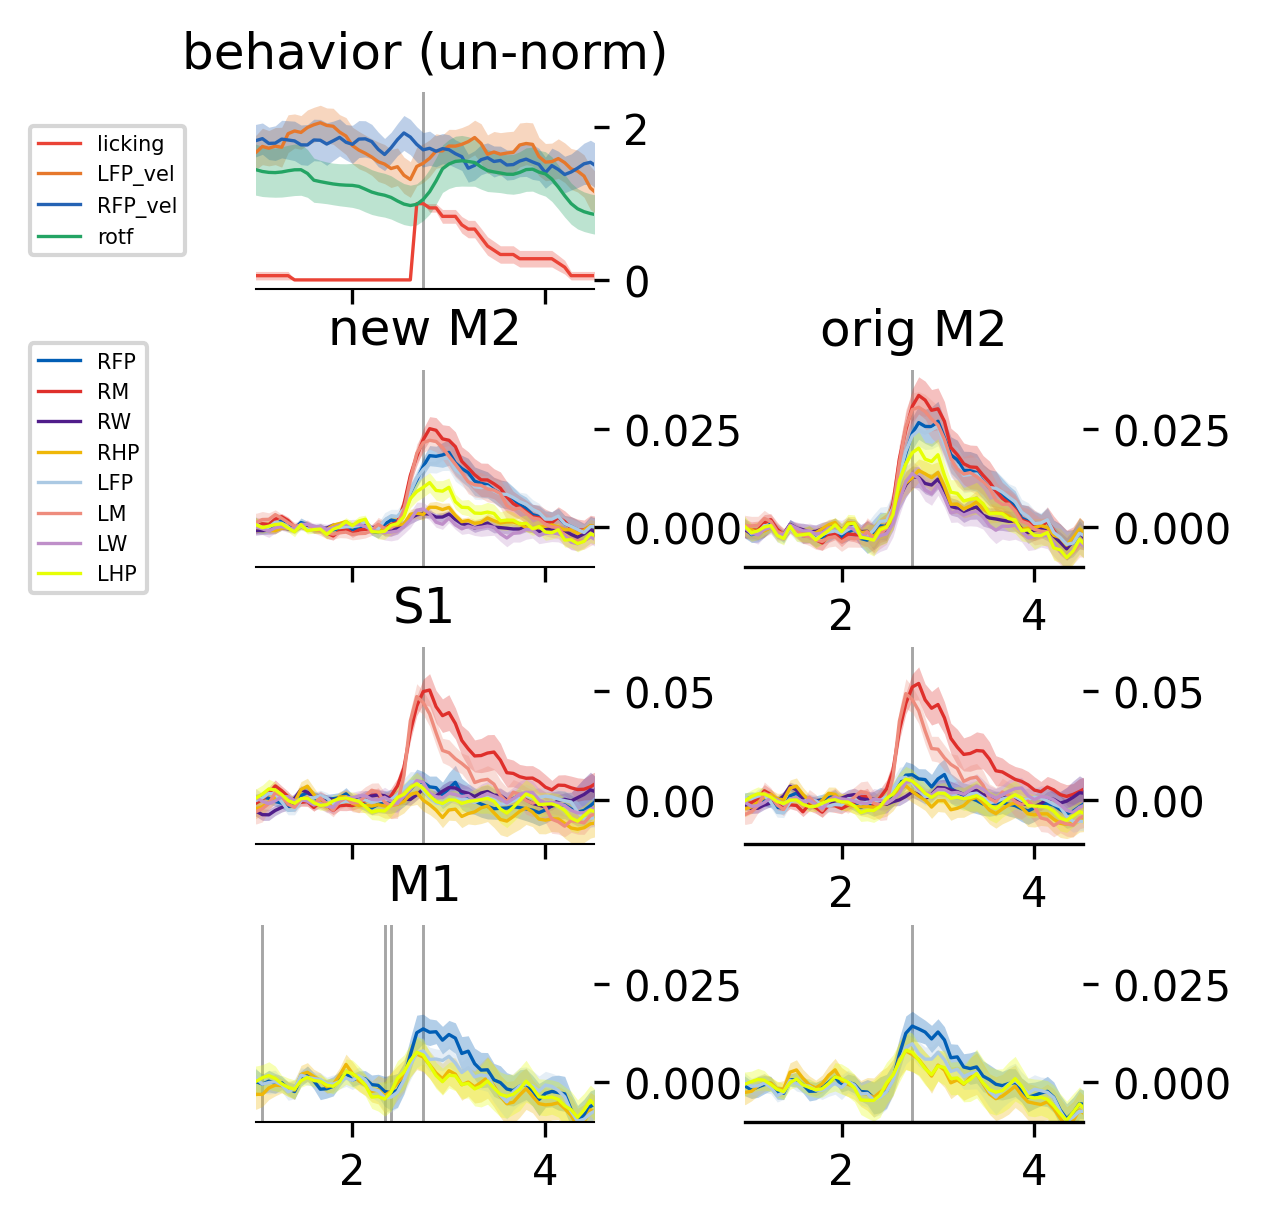

In [33]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)



# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;


# webcam image
# x_start = x_offset
# x_stop = x_start+8
# ax0 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
x_start = x_offset
x_stop = x_start+5
# jrgeco snapshots for 'run'''''
# ax1 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
# colorbar for jrgeco snapshot
x_start = x_stop
x_stop = x_start+1
# ax991 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])
# time courses for behaviors
x_start = x_stop+1
x_stop = x_start+5
ax5 = fig.add_subplot(gs[y_offset-5:y_offset-2,x_start:x_stop])
# time courses for M2
x_start = x_start
x_stop = x_start+5
ax2 = fig.add_subplot(gs[y_offset-1:y_offset+2,x_start:x_stop])
ax200 = fig.add_subplot(gs[y_offset-1:y_offset+2,x_stop+2:x_stop+7])
# time courses for S1
x_start = x_start
x_stop = x_start+5
ax3 = fig.add_subplot(gs[y_offset+3:y_offset+6,x_start:x_stop])
ax300 = fig.add_subplot(gs[y_offset+3:y_offset+6,x_stop+2:x_stop+7])
# time courses for M1
x_start = x_start
x_stop = x_start+5
ax4 = fig.add_subplot(gs[y_offset+7:y_offset+10,x_start:x_stop])
ax400 = fig.add_subplot(gs[y_offset+7:y_offset+10,x_stop+2:x_stop+7])
# # webcam
# ax0.imshow(dict_webcam_img['lick'],cmap='gray')


T_total = dict_H_dbsl_mice[mouse_id].shape[1]
t_ax_trimmed = np.divide(range(T_total),fs_here)

# time courses -M2
for i_choice_M2,M2_bdp in enumerate(list_choice_M2_l_n_r):
    data_here = jrgeco2plot_M2[M2_bdp][:,:]
    avg = np.mean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax200.plot(t_ax_trimmed,avg,label=M2_bdp,color=palatte_dict[M2_bdp],linewidth=0.8)
    ax200.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[M2_bdp],alpha=0.3,lw=0)

for i_bdp,bdp in enumerate(list_choice_M2_l_n_r):
    ind_in_list = all_bdps.index(bdp+'_M2')
    data_here = H_nnls_bouts[ind_in_list,:,:] 
    avg = np.mean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax2.plot(t_ax_trimmed,avg,label=bdp,color=palatte_dict[bdp],linewidth=0.8)
    ax2.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp],alpha=0.3,lw=0)

    

# time courses -S1    
for i_choice_M2,bdp in enumerate(list_choice_M2_l_n_r):
    ind_in_list = all_bdps.index(bdp+'_S1')
    data_here = H_nnls_bouts[ind_in_list,:,:]
    avg = np.mean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax3.plot(t_ax_trimmed,avg,label=bdp,color=palatte_dict[bdp],linewidth=0.8)
    ax3.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp],alpha=0.3,lw=0)
     
# time courses -S1    
for i_choice_M2,M2_bdp in enumerate(list_choice_M2_l_n_r):
    data_here = dict_H_dbsl_mice[mouse_id][sensory_ind_here[M2_bdp],:,:]
    avg = np.mean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax300.plot(t_ax_trimmed,avg,label=M2_bdp,color=palatte_dict[M2_bdp],linewidth=0.8)
    ax300.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[M2_bdp],alpha=0.3,lw=0)
 
for i_choice_M2,bdp in enumerate(all_bdps_list_M1):
    ind_in_list = all_bdps.index(bdp+'_M1')
    data_here = H_nnls_bouts[ind_in_list,:,:]
    avg = np.mean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax4.plot(t_ax_trimmed,avg,label=bdp,color=palatte_dict[bdp],linewidth=0.8)
    ax4.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp],alpha=0.3,lw=0)
     
# time courses -M1    
for i_choice_M2,M2_bdp in enumerate(all_bdps_list_M1):
    data_here = dict_H_dbsl_mice[mouse_id][M1_ind_from_coherence[M2_bdp],:,:]
    avg = np.mean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax400.plot(t_ax_trimmed,avg,label=M2_bdp,color=palatte_dict[M2_bdp],linewidth=0.8)
    ax400.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[M2_bdp],alpha=0.3,lw=0)
        
# time courses -behaviors
colors2=sns.color_palette()
for i_choice_behavior,behavior_here in enumerate(list_select_behavior_2show):
    data_here = dict_collection_mice[mouse_id][behavior_here][90-40:90+60,:]
    avg = np.mean(data_here,axis=1)
    sem = stats.sem(data_here,axis=1)
    ax5.plot(t_ax_trimmed,avg,label=behavior_here[2:],color=palatte_behavior_dict[behavior_here],linewidth=0.8)
    ax5.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_behavior_dict[behavior_here],alpha=0.3,lw=0)
    

    

ax2.set_xlim([1,4.5])
ax2.axvline(t_ax_trimmed[T_PRE_all_mice+1],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)
ax2.set_ylim([-0.01,0.04])

ax200.set_xlim([1,4.5])
ax200.axvline(t_ax_trimmed[T_PRE_all_mice+1],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)
ax200.set_ylim([-0.01,0.04])
# ax2.axhline(0,linewidth=1,color='gray',alpha=0.7,zorder=-999)

ax3.set_xlim([1,4.5])
ax3.axvline(t_ax_trimmed[T_PRE_all_mice+1],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)
ax3.set_ylim([-0.02,0.07])
# ax3.axhline(0,linewidth=1,color='gray',alpha=0.7,zorder=-999)
ax300.set_xlim([1,4.5])
ax300.axvline(t_ax_trimmed[T_PRE_all_mice+1],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)
ax300.set_ylim([-0.02,0.07])

ax4.set_xlim([1,4.5])
ax4.axvline(t_ax_trimmed[T_PRE_all_mice+1],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)
ax4.set_ylim([-0.01,0.04])
ax400.set_xlim([1,4.5])
ax400.axvline(t_ax_trimmed[T_PRE_all_mice+1],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)
ax400.set_ylim([-0.01,0.04])
# ax3.axhline(0,linewidth=1,color='gray',alpha=0.7,zorder=-999)

ax5.set_xlim([1,4.5])
ax5.axvline(t_ax_trimmed[T_PRE_all_mice+1],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)


# ax2.axvspan(t_ax_trimmed[12],t_ax_trimmed[14],color='gray',alpha=0.1,zorder=-999,linewidth=0)
# ax3.axvspan(t_ax_trimmed[12],t_ax_trimmed[14],color='gray',alpha=0.1,zorder=-999,linewidth=0)

###################################
# jrgeco
# sbp1 = ax1.imshow(np.mean(np.mean(dict_full_jrgeco_dbsl_mice['cm229'][:,:,T_PRE_all_mice:T_PRE_all_mice+2,:],axis=2),axis=-1),cmap='icefire',vmin=-0.04,vmax=0.04)
# # add scatter plot
# for i_bdp, bdp_S1 in enumerate(list_choice_M2):
#     region_number = M1_ind_from_coherence[bdp_S1]
#     ax1.scatter(node_coords_here[region_number,1], node_coords_here[region_number,0], marker="D", s=6, c=palatte_dict[bdp_S1], zorder=2)
#     region_number = sensory_ind_here[bdp_S1]
#     ax1.scatter(node_coords_here[region_number,1], node_coords_here[region_number,0], marker='*', s=6, c=palatte_dict[bdp_S1], zorder=2)
#     ax1.scatter(node_coords_M2[bdp_S1][0], node_coords_M2[bdp_S1][1], s=3, c=palatte_dict[bdp_S1], zorder=2)


# #color bar
# cb = fig.colorbar(sbp1, cax=ax991,fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));
# cb.ax.tick_params(labelsize=7,length=2,color='black')
# cb.ax.yaxis.tick_right()       
# cb.outline.set_edgecolor('black')
# cb.outline.set_linewidth(0.5)
# tick_locator = ticker.MaxNLocator(nbins=3)
# cb.locator = tick_locator
# cb.update_ticks()
# ax991.set_aspect(100);ax991.set_anchor('W')

###################################
######
    
# exec("ax{}.set_xticks([]);ax{}.set_yticks([]);ax{}.set_xticks([]);ax{}.set_yticks([])".format(1,1,1,1))
# ax1.set_xlim([15,256]);ax1.set_ylim([256,15])
ax5.set_xticklabels([])
ax2.set_xticklabels([])
ax3.set_xticklabels([])

for axis in ['top','right','left','bottom']:
    for i_ax in range(0,7):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue
            
            
for axis in ['top','right','left']:
    for i_ax in range(2,6):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        exec("ax{}.yaxis.tick_right()".format(i_ax))

for i_ax in [200,300,400]:
    for axis in ['top','right','left']:
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        exec("ax{}.yaxis.tick_right()".format(i_ax))
 

ax2.set_title('new M2')
ax3.set_title('S1')
ax4.set_title('M1')
ax200.set_title('orig M2')
ax5.set_title('behavior (un-norm)')
ax2.legend(loc='center left', bbox_to_anchor=(-0.7, 0.5),fontsize=5)
ax5.legend(loc='center left', bbox_to_anchor=(-0.7, 0.5),fontsize=5)
# plt.savefig('lick-during-run-cm229.svg',format='svg',dpi=300)

ax4.axvline(t_ax_trimmed[35],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)
ax4.axvline(t_ax_trimmed[16],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)
ax4.axvline(t_ax_trimmed[16+20],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)
# ax3.axvline(t_ax_trimmed[1356],linewidth=0.7,color='gray',alpha=0.7,zorder=-999)

# We make movies better

In [36]:
# from skimage import measure
# contours = {}
# filled_bw = scipy.ndimage.morphology.binary_fill_holes(W_masked_M2[:,:,0]>-100)
# contours['M2'] = measure.find_contours(filled_bw, 0.8)
# filled_bw = scipy.ndimage.morphology.binary_fill_holes(W_masked_S1M1[:,:,0]>-100)
# contours['S1M1'] = measure.find_contours(filled_bw, 0.8)

In [34]:
recon_full_jrgeco=[]
for i_bout in range(B):
    H_nnls_this_bout = H_nnls_bouts[:,:,i_bout]
    recon_full_jrgeco.append(np.dot(W_masked.reshape((256*256,-1)),H_nnls_this_bout))
recon_full_jrgeco=np.stack(recon_full_jrgeco,axis=2)




In [35]:
ss=recon_full_jrgeco.shape
residuals = full_jrgeco - recon_full_jrgeco.reshape((256,256,ss[1],ss[2]))

In [36]:
IDX_mask = IDX_sorted>-100
IDX_mask = IDX_mask.astype('float')
IDX_mask[IDX_mask==0]=np.nan

In [37]:
AVG_full_jrgeco = np.mean(full_jrgeco,axis=-1)
AVG_residual = np.mean(residuals,axis=-1)
AVG_residual = np.multiply(AVG_residual,np.repeat(IDX_mask[:,:,np.newaxis],repeats=AVG_residual.shape[-1],axis=2))

In [39]:
extra_bdp_color_dict = {
    'ALM-M2':palatte_dict['ALM'], 'RV-S1M1':palatte_dict['RV'],
                        'LV-S1M1':palatte_dict['RV'],'RSP-S1M1':palatte_dict['RSP'],
                        
                        'RALM':palatte_dict['ALM'],'LALM':palatte_dict['ALM'],
                        'RRSP':palatte_dict['RSP'],'LRSP':palatte_dict['RSP'],
                        
                  'RFP_M1_extra':palatte_dict['LFP'],
                        'LFP_M1_extra':palatte_dict['LFP'],
                'RholeMOp' : '#ff964f', #pastel orange
                'LholeMOp' : '#ff964f', #pastel orange
                'Rposterior':'greenyellow',
                'Lposterior':'greenyellow',

                       'median':'gray'}

In [46]:
######################################################################
import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]
for bdp_w_label in extra_bdp_color_dict:
    dict_rgb_colors[bdp_w_label] = [mcolors.hex2color(extra_bdp_color_dict[bdp_w_label])]

dict_rgb_colors['LV']=dict_rgb_colors['RV-S1M1']
dict_rgb_colors['RV']=dict_rgb_colors['RV-S1M1']

SCALE_VALUE = 30

# Create the blended movie (avg time course)
T = H_nnls_bouts[:,:,:].shape[1]
blended_movie =  [] #= np.zeros((256, 256, 3,T), dtype=np.float32)

# Blend images with colors
for t in range(T):
    blended_image = np.zeros((256, 256, 3),dtype=np.float32)
    for i_M2, bdp in enumerate(['RFP', 'RHP', 'RW', 'RM', 'LFP', 'LHP', 'LW', 'LM']):
        color = dict_rgb_colors[bdp.replace('L','R')]
        ind_in_list = all_bdps.index(bdp+'_M2')
        image = W_masked[:,:,ind_in_list]
        H_nnls_bouts_avged = np.nanmean(H_nnls_bouts[ind_in_list,:,:],-1) 
        H_nnls_bouts_avged = H_nnls_bouts_avged * SCALE_VALUE # scale it up 
        scaling = H_nnls_bouts_avged[t]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color
    
    for i_M2, bdp in enumerate(['RFP', 'RHP', 'RW', 'RM', 'LFP', 'LHP', 'LW', 'LM']):
        color = dict_rgb_colors[bdp.replace('L','R')]
        ind_in_list = all_bdps.index(bdp+'_S1')
        image = W_masked[:,:,ind_in_list]
        H_nnls_bouts_avged = np.nanmean(H_nnls_bouts[ind_in_list,:,:],-1) * SCALE_VALUE # scale it up
        scaling = H_nnls_bouts_avged[t]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color

    for i_M2, bdp in enumerate(all_bdps_list_M1):
        color = dict_rgb_colors[bdp.replace('L','R')]
        ind_in_list = all_bdps.index(bdp+'_M1')
        image = W_masked[:,:,ind_in_list]
        H_nnls_bouts_avged = np.nanmean(H_nnls_bouts[ind_in_list,:,:],-1) * SCALE_VALUE # scale it up
        scaling = H_nnls_bouts_avged[t]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color
        
    # FORELIMB
    for i_M2, bdp in enumerate(['RFP', 'LFP']):
        color = dict_rgb_colors[bdp+'_M1_extra']
        ind_in_list = all_bdps.index(bdp+'_M1_extra')
        image = W_masked[:,:,ind_in_list]
        H_nnls_bouts_avged = np.nanmean(H_nnls_bouts[ind_in_list,:,:],-1) * SCALE_VALUE # scale it up
        scaling = H_nnls_bouts_avged[t]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color
        
    blended_movie.append(blended_image)
    
blended_movie = np.stack(blended_movie,axis=3)
# # Ensure values are within valid range
# blended_movie = np.clip(blended_movie, 0, 1)

######################################################################
######################################################################
######################################################################
######################################################################
######################################################################
######################################################################
######################################################################
######################################################################
######################################################################
######################################################################
blended_median_movie =  []
for t in range(T):
    blended_median_image = np.zeros((256, 256, 3),dtype=np.float32)
    
    for i_key,key in enumerate(all_bdps_extra):
        # if key.split('-')[1]=='M2':
        #     ind_in_list = extra_bdp_dict[key]
        #     W_masked_2show = W_masked_S1M2M1[:,:,ind_in_list]
        #     H_nnls_bouts_avged = np.nanmean(H_nnls_bouts[ind_in_list,:,:],-1) * SCALE_VALUE # scale it up
        # if key.split('-')[0] in ['RV','LV','RSP']:
        if i_key < 6:
            ind_in_list = all_bdps.index(key)
            W_masked_2show = W_masked[:,:,ind_in_list]      
            H_nnls_bouts_avged = np.nanmean(H_nnls_bouts[ind_in_list,:,:],-1) * SCALE_VALUE # scale it up

            image = W_masked_2show
            scaling = H_nnls_bouts_avged[t]
            image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)

            median_color = dict_rgb_colors[key]
            blended_median_image += image_scaled[:, :, np.newaxis] * median_color
    
    # median
    ind_in_list = -2
    W_masked_2show = W_masked[:,:,ind_in_list]      
    H_nnls_bouts_avged = np.nanmean(H_nnls_bouts[ind_in_list,:,:],-1) * SCALE_VALUE # scale it up
    image = W_masked_2show
    scaling = H_nnls_bouts_avged[t]
    image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
    median_color = dict_rgb_colors['median']
    blended_median_image += image_scaled[:, :, np.newaxis] * median_color
    
    # ALM
    # for ind_in_list in [0,1]:
    #     W_masked_2show = W_masked_S1M2M1[:,:,ind_in_list]      
    #     H_nnls_bouts_avged = np.nanmean(H_nnls_bouts[ind_in_list,:,:],-1) * SCALE_VALUE # scale it up
    #     image = W_masked_2show
    #     scaling = H_nnls_bouts_avged[t]
    #     image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
    #     median_color = dict_rgb_colors['ALM']
    #     blended_median_image += image_scaled[:, :, np.newaxis] * median_color
    
    blended_median_movie.append(blended_median_image)

blended_median_movie = np.stack(blended_median_movie,axis=3)

# Ensure values are within valid range
# blended_median_movie = np.clip(blended_median_movie, 0, 1)

blended_whole_movie = np.append(blended_movie,blended_median_movie,axis=2)
blended_whole_movie = np.clip(blended_whole_movie, 0, 1)
blended_movie = blended_whole_movie[:,:,:3,:]
blended_median_movie = blended_whole_movie[:,:,3:,:]

In [40]:
contours = load_pickle(figure_config_root+'M2-S1M1_area_segment_'+mouse)['contours']

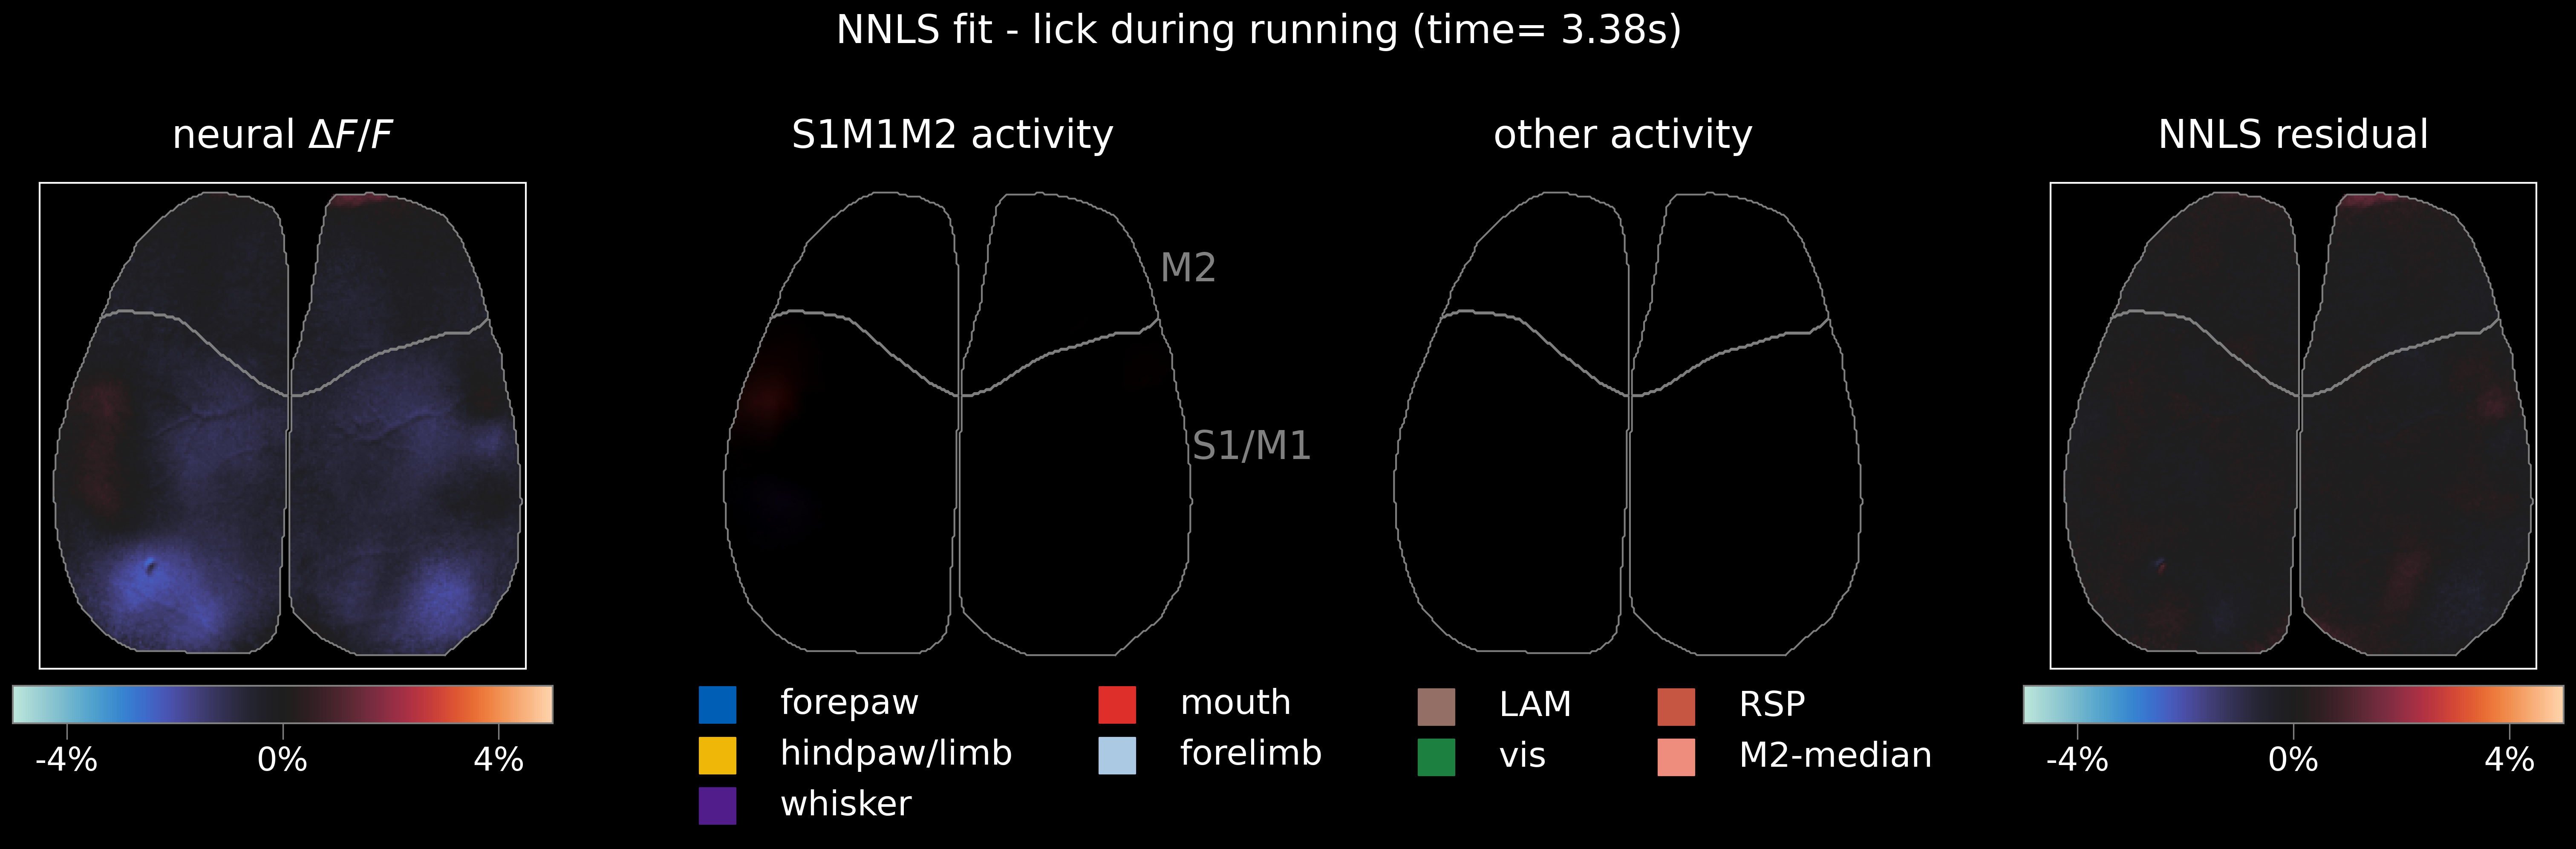

In [48]:
from matplotlib import animation
from IPython.display import HTML
from matplotlib.gridspec import GridSpec
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
plt.style.use('dark_background')
font_size_title = 22
fig = plt.figure(figsize=(28,8),dpi=300)
# gs = GridSpec(7,25)
gs = fig.add_gridspec(8,25)
y_offset = 1;x_offset=0;y_gap=1;x_gap=1;x_width=5
x_start = x_offset
for i_ax in range(4):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_start+5])".format(i_ax))
    x_start = x_start+5+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    
ax990 = fig.add_subplot(gs[y_offset+5:y_offset+6,x_offset:x_offset+5])
ax993 = fig.add_subplot(gs[y_offset+5:y_offset+6,x_offset+5*3+x_gap*2+1:x_offset+5*3+x_gap*2+1+5])

txt_title0 = ax0.set_title(r'neural $\Delta F/F$',y=1.05,fontsize=font_size_title)
txt_title1 = ax1.set_title('S1M1M2 activity',y=1.05,fontsize=font_size_title)
txt_title2 = ax2.set_title('other activity',y=1.05,fontsize=font_size_title)
txt_title3 = ax3.set_title('NNLS residual',y=1.05,fontsize=font_size_title)


sbp0 = ax0.imshow(AVG_full_jrgeco[:,:,5],vmin=-0.05,vmax=0.05,cmap='icefire')
sbp1 = ax1.imshow(blended_movie[:,:,:,5])
sbp2 = ax2.imshow(blended_median_movie[:,:,:,5])
sbp3 = ax3.imshow(AVG_residual[:,:,5],vmin=-0.05,vmax=0.05,cmap='icefire')

for axis in ['top','right','left','bottom']:
    for i_ax in [1,2]:
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
    for i_ax in [0,3]:
        exec("ax{}.spines[axis].set_linewidth(1)".format(i_ax))  
        
for i_ax in range(4):
    for contour in contours['M2']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)".format(i_ax))
    for contour in contours['S1M1']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)".format(i_ax))

        
#color bar
for i_ax in ['0','3']:
    exec("cb = fig.colorbar(sbp{}, cax=ax99{},fraction=0.5,orientation='horizontal',format=FuncFormatter(fmt));".format(i_ax,i_ax))
    cb.ax.tick_params(labelsize=18.5,length=9,color='gray')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(1)
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    exec("ax99{}.set_aspect(0.007);ax99{}.set_anchor('N')".format(i_ax,i_ax))

    
bdp_short_dict = {'RFP':'forepaw','RHP':'hindpaw/limb','RM':'mouth',
                  'RW':'whisker','RFP_M1_extra':'forelimb'}
palatte_dict['RFP_M1_extra']=palatte_dict['LFP']
for bdp in ['RFP','RHP','RW','RM','RFP_M1_extra']:
    ax1.scatter(300,300,label=bdp_short_dict[bdp],marker='s',s=400,color=palatte_dict[bdp])
ax1.legend(bbox_to_anchor=(-0.12,-0.38), loc="lower left", frameon=False,
                # bbox_transform=fig.transFigure,
           ncol=2,fontsize=19.5)

extra_short_dict = {'ALM-M2':'LAM','RV-S1M1':'vis','RSP-S1M1':'RSP',
                  'RFP_M1_extra-S1M1':'forelimb','median':'M2-median'}
for bdp in ['ALM-M2','RV-S1M1','RSP-S1M1','median']:
    ax2.scatter(300,300,label=extra_short_dict[bdp],marker='s',s=400,color=extra_bdp_color_dict[bdp])
ax2.legend(bbox_to_anchor=(-0.02,-0.28), loc="lower left", frameon=False,
                # bbox_transform=fig.transFigure,
           ncol=2,fontsize=19.5)

txt_title = plt.text(-0.27,18,'NNLS fit - lick during running (time= s)',fontsize=font_size_title)
# plt.scatter(18*np.ones(20),np.linspace(-0.29,-0.1,20),color='white')
time_stamp = np.linspace(-16/15,(AVG_full_jrgeco.shape[-1]-16)/15,AVG_full_jrgeco.shape[-1])

plt.text(-0.21,11.7,'M2',fontsize=font_size_title,color='gray')
plt.text(-0.204,7,'S1/M1',fontsize=font_size_title,color='gray')

def drawframe(n):
    sbp0.set_array(AVG_full_jrgeco[:,:,n])
    sbp1.set_array(blended_movie[:,:,:,n])
    sbp2.set_array(blended_median_movie[:,:,:,n])
    sbp3.set_array(AVG_residual[:,:,n])
    txt_title.set_text('NNLS fit - lick during running (time= {:.2f}s)'.format(time_stamp[n]))
    return (sbp0,sbp2,
            sbp3,sbp1,
            txt_title)
# blit=True re-draws only the parts that have changed. # *interval* draws a new frame every *interval* milliseconds.
anim = animation.FuncAnimation(fig, drawframe, frames=np.arange(16,67), interval=15, blit=True)
# display(HTML(anim.to_html5_video()))
# or to save as a file
anim.save('CLS_fit_lick_{}.mp4'.format(mouse), fps=10, extra_args=['-vcodec', 'libx264'])



# SAVE DATA

In [49]:
dict_all_data={}

all_bdps_w_order = ['RFP','LFP' ,'RM','LM', 'RW','LW', 'RHP', 'LHP']
array_S1,array_M1,array_M2 =[],[],[]

time_range_to_save = range(16,67)
for i_bdp,bdp in enumerate(all_bdps_w_order):
    M2 = H_nnls_bouts[all_bdps.index(bdp+'_M2'),time_range_to_save,:]
    array_M2.append(M2)
    S1 = H_nnls_bouts[all_bdps.index(bdp+'_S1'),time_range_to_save,:]
    array_S1.append(S1)
for i_bdp,bdp in enumerate(all_bdps_list_M1):
    M1 = H_nnls_bouts[all_bdps.index(bdp+'_M1'),time_range_to_save,:]
    array_M1.append(M1)
array_S1 = np.stack(array_S1,axis=0) 
array_M1 = np.stack(array_M1,axis=0)
array_M2 = np.stack(array_M2,axis=0)


dict_behaviors = {}
for i_choice_behavior,behavior_here in enumerate(list_select_behavior_2show):
    data_here = dict_collection_mice[mouse_id][behavior_here][90-40:90+60,:]
    dict_behaviors[behavior_here] = data_here[time_range_to_save,:]

AVG_full_jrgeco_2_save = AVG_full_jrgeco[:,:,time_range_to_save]
blended_movie_2_save = blended_movie[:,:,:,time_range_to_save]

dict_all_data = {'array_S1':array_S1,
                          'array_M1':array_M1,
                          'array_M2':array_M2,
                 
                 'H_nnls_bouts':H_nnls_bouts[:,time_range_to_save,:],
                 'all_bdps':all_bdps,
                          'dict_behaviors':dict_behaviors,
                          'T_PRE' :21,
                          'AVG_full_jrgeco_2_save':AVG_full_jrgeco_2_save,
                          'blended_movie_2_save':blended_movie_2_save}

# STATS

In [47]:
dict_all_stats={}



In [48]:
time_range = range(31,59)
time_range_updated = range(36,54)

In [49]:

all_bdps_w_order = ['RFP','LFP' ,'RM','LM', 'RW','LW', 'RHP', 'LHP']
array_S1,array_M1,array_M2 =[],[],[]

# time_range = range(10,len_move_2_rise+len_rise_2_lick)
for i_bdp,bdp in enumerate(all_bdps_w_order):
    M2 = H_nnls_bouts[all_bdps.index(bdp+'_M2'),time_range_updated,:]
    array_M2.append(M2)
    S1 = H_nnls_bouts[all_bdps.index(bdp+'_S1'),time_range_updated,:]
    array_S1.append(S1)
for i_bdp,bdp in enumerate(all_bdps_list_M1):  
    M1 = H_nnls_bouts[all_bdps.index(bdp+'_M1'),time_range_updated,:]
    array_M1.append(M1)
array_S1 = np.stack(array_S1,axis=0) 
array_M1 = np.stack(array_M1,axis=0)
array_M2 = np.stack(array_M2,axis=0)

total_bouts = array_S1.shape[-1]
total_num_bdps = array_S1.shape[0]
array_cov_S1M1 = []
array_cov_S1M2 = []
array_cov_M1M2 = []
for i_bout in range(total_bouts):
    S1_this_bout = array_S1[:,:,i_bout];S1_this_bout=S1_this_bout[:,~np.isnan(S1_this_bout[0,:])]
    M1_this_bout = array_M1[:,:,i_bout];M1_this_bout=M1_this_bout[:,~np.isnan(M1_this_bout[0,:])]
    M2_this_bout = array_M2[:,:,i_bout];M2_this_bout=M2_this_bout[:,~np.isnan(M2_this_bout[0,:])]
    a=np.cov(np.concatenate((S1_this_bout,M1_this_bout),0),bias=True)
    cov_S1M1 = a[:total_num_bdps,total_num_bdps:] # S1 on the y-axis, M1 on x-axis
    a=np.cov(np.concatenate((S1_this_bout,M2_this_bout),0),bias=True)
    cov_S1M2 = a[:total_num_bdps,total_num_bdps:] # S1 on the y-axis, M2 on x-axis
    a=np.cov(np.concatenate((M1_this_bout,M2_this_bout),0),bias=True)
    cov_M1M2 = a[:total_num_bdps,total_num_bdps:] # M1 on the y-axis, M2 on x-axis
    array_cov_S1M1.append(cov_S1M1)
    array_cov_S1M2.append(cov_S1M2)
    array_cov_M1M2.append(cov_M1M2)
    
array_cov_S1M1 = np.stack(array_cov_S1M1,axis=0) 
array_cov_S1M2 = np.stack(array_cov_S1M2,axis=0) 
array_cov_M1M2 = np.stack(array_cov_M1M2,axis=0) 

dict_all_stats = {'array_cov_S1M1':array_cov_S1M1,
                                   'array_cov_S1M2':array_cov_S1M2,
                                        'array_cov_M1M2':array_cov_M1M2}

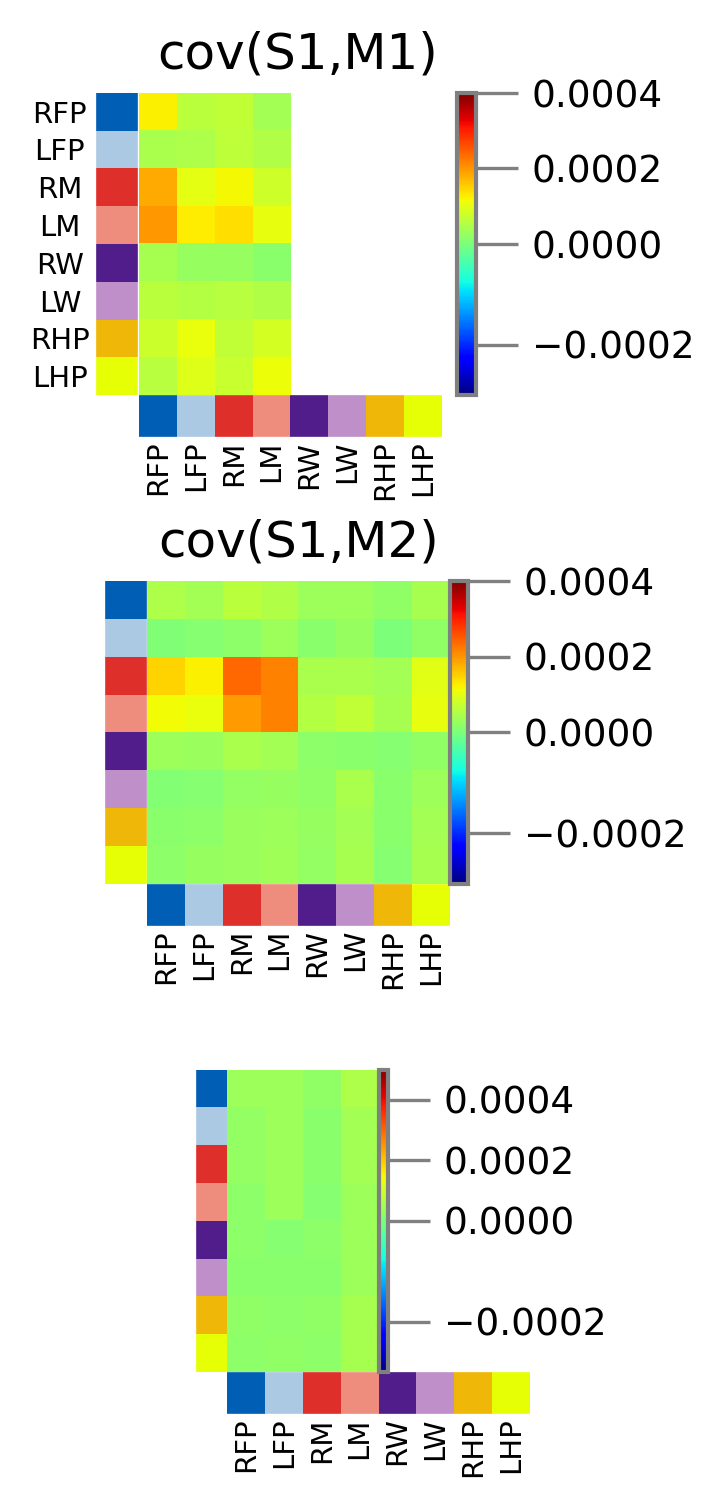

In [55]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib import colors
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)

# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5
for i_ax in range(1): # 3 mice S1M1
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    # x_start = x_stop
    # x_stop = x_start+1
    exec("ax{}.axis('off')".format(i_ax))
    # colorbar 
    # exec("ax99{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop+2
    x_stop = x_start+5
    
y_start = y_offset+7; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5
for i_ax in range(1,2): # 3 mice S1M2
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    # x_start = x_stop
    # x_stop = x_start+1
    exec("ax{}.axis('off')".format(i_ax))
    # colorbar 
    # exec("ax99{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop+2
    x_stop = x_start+5
 
y_start = y_offset+14; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5
for i_ax in range(2,3): # 3 mice S1M2
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    # x_start = x_stop
    # x_stop = x_start+1
    exec("ax{}.axis('off')".format(i_ax))
    # colorbar 
    # exec("ax99{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop+2
    x_stop = x_start+5
############################################################

divnorm=colors.TwoSlopeNorm(vmin=-0.0003, vcenter=0., vmax=0.0004) 
i_ax=0
exec("sbp{} = ax{}.imshow(np.mean(array_cov_S1M1,0),cmap='jet',norm=divnorm)".format(i_ax,i_ax))
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
exec("div = make_axes_locatable(ax{})".format(i_ax))
cax = div.append_axes('right', '6%', '0%')
exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical')".format(i_ax))#,format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=9,length=10,color='gray')
cb.ax.yaxis.tick_right()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))
start=-0.5;
for bdp in all_bdps_w_order:
    stop = start + 1
    ax0.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=10, clip_on=False,solid_capstyle='butt')
    ax0.plot([-.07,-.07],[start,stop], color=palatte_dict[bdp],
            transform=trans_y,linewidth=10, clip_on=False,solid_capstyle='butt')
    ax0.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    if i_ax == 0:
        ax0.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")
    start = stop
        
divnorm=colors.TwoSlopeNorm(vmin=-0.0003, vcenter=0., vmax=0.0004) 
i_ax = 1

exec("sbp{} = ax{}.imshow(np.mean(array_cov_S1M2,0),cmap='jet',norm=divnorm)".format(i_ax,i_ax))

from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
exec("div = make_axes_locatable(ax{})".format(i_ax))
cax = div.append_axes('right', '6%', '0%')
exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical')".format(i_ax))#,format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=9,length=10,color='gray')
cb.ax.yaxis.tick_right()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)

exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))

start=-0.5;
for bdp in all_bdps_w_order:
    stop = start + 1
    ax1.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=10, clip_on=False,solid_capstyle='butt')
    ax1.plot([-.07,-.07],[start,stop], color=palatte_dict[bdp],
            transform=trans_y,linewidth=10, clip_on=False,solid_capstyle='butt')
    ax1.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    if i_ax == 3:
        ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")
    start = stop

#########
divnorm=colors.TwoSlopeNorm(vmin=-0.0003, vcenter=0., vmax=0.0005) 
i_ax = 2

exec("sbp{} = ax{}.imshow(np.mean(array_cov_M1M2,0),cmap='jet',norm=divnorm)".format(i_ax,i_ax))

from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
exec("div = make_axes_locatable(ax{})".format(i_ax))
cax = div.append_axes('right', '6%', '0%')
exec("cb = fig.colorbar(sbp{}, cax=cax,orientation='vertical')".format(i_ax))#,format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=9,length=10,color='gray')
cb.ax.yaxis.tick_right()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)

exec("trans_x = ax{}.get_xaxis_transform()".format(i_ax))
exec("trans_y = ax{}.get_yaxis_transform()".format(i_ax))

start=-0.5;
for bdp in all_bdps_w_order:
    stop = start + 1
    ax1.plot([start,stop],[-0.07,-0.07], color=palatte_dict[bdp],
            transform=trans_x,linewidth=10, clip_on=False,solid_capstyle='butt')
    ax1.plot([-.07,-.07],[start,stop], color=palatte_dict[bdp],
            transform=trans_y,linewidth=10, clip_on=False,solid_capstyle='butt')
    ax1.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    if i_ax == 3:
        ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")
    start = stop


ax0.set_title('cov(S1,M1)')
ax1.set_title('cov(S1,M2)')
plt.subplots_adjust(hspace=2)


In [56]:
dict_all_stats = {'array_cov_S1M1':array_cov_S1M1,
                                   'array_cov_S1M2':array_cov_S1M2,
                                        'array_cov_M1M2':array_cov_M1M2,
                 'all_bdps_w_order':all_bdps_w_order}

In [57]:
dict_all = {'dict_all_stats':dict_all_stats,
           'dict_all_data':dict_all_data}

In [58]:
save_path_here = str(FIGURES / "figure8") + "/"
save_pickle(dict_all,save_path_here+'dict_all_lick_'+mouse_id)


# Save data to make movie 8 (CLS single-trial)

In [42]:
######################################################################
import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]
for bdp_w_label in extra_bdp_color_dict:
    dict_rgb_colors[bdp_w_label] = [mcolors.hex2color(extra_bdp_color_dict[bdp_w_label])]

dict_rgb_colors['LV']=dict_rgb_colors['RV-S1M1']
dict_rgb_colors['RV']=dict_rgb_colors['RV-S1M1']

SCALE_VALUE = 30

# Create the blended movie (avg time course)
T = H_nnls_bouts[:,:,:].shape[1]
B = H_nnls_bouts[:,:,:].shape[-1]

M_blended_movie =[]
M_blended_median_movie = []
# Blend images with colors
for bout in range (B):
    blended_movie =  [] # = np.zeros((256, 256, 3,T), dtype=np.float32)
    for t in range(T):
        blended_image = np.zeros((256, 256, 3),dtype=np.float32)
        for i_M2, bdp in enumerate(['RFP', 'RHP', 'RW', 'RM', 'LFP', 'LHP', 'LW', 'LM']):
            color = dict_rgb_colors[bdp.replace('L','R')]
            ind_in_list = all_bdps.index(bdp+'_M2')
            image = W_masked[:,:,ind_in_list]
            H_nnls_bouts_avged = H_nnls_bouts[ind_in_list,:,bout]
            H_nnls_bouts_avged = H_nnls_bouts_avged * SCALE_VALUE # scale it up 
            scaling = H_nnls_bouts_avged[t]
            image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
            blended_image += image_scaled[:, :, np.newaxis] * color

        for i_M2, bdp in enumerate(['RFP', 'RHP', 'RW', 'RM', 'LFP', 'LHP', 'LW', 'LM']):
            color = dict_rgb_colors[bdp.replace('L','R')]
            ind_in_list = all_bdps.index(bdp+'_S1')
            image = W_masked[:,:,ind_in_list]
            H_nnls_bouts_avged = H_nnls_bouts[ind_in_list,:,bout] * SCALE_VALUE # scale it up
            scaling = H_nnls_bouts_avged[t]
            image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
            blended_image += image_scaled[:, :, np.newaxis] * color

        for i_M2, bdp in enumerate(['RFP', 'RHP', 'LFP', 'LHP']):
            color = dict_rgb_colors[bdp.replace('L','R')]
            ind_in_list = all_bdps.index(bdp+'_M1')
            image = W_masked[:,:,ind_in_list]
            H_nnls_bouts_avged = H_nnls_bouts[ind_in_list,:,bout] * SCALE_VALUE # scale it up
            scaling = H_nnls_bouts_avged[t]
            image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
            blended_image += image_scaled[:, :, np.newaxis] * color

        # FORELIMB
        for i_M2, bdp in enumerate(['RFP', 'LFP']):
            color = dict_rgb_colors[bdp+'_M1_extra']
            ind_in_list = all_bdps.index(bdp+'_M1_extra')
            image = W_masked[:,:,ind_in_list]
            H_nnls_bouts_avged = H_nnls_bouts[ind_in_list,:,bout] * SCALE_VALUE # scale it up
            scaling = H_nnls_bouts_avged[t]
            image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
            blended_image += image_scaled[:, :, np.newaxis] * color

        blended_movie.append(blended_image)

    blended_movie = np.stack(blended_movie,axis=3)
    # # Ensure values are within valid range
    # blended_movie = np.clip(blended_movie, 0, 1)

    ######################################################################
    ######################################################################
    ######################################################################
    ######################################################################
    ######################################################################
    ######################################################################
    ######################################################################
    ######################################################################
    ######################################################################
    ######################################################################
    blended_median_movie =  []
    for t in range(T):
        blended_median_image = np.zeros((256, 256, 3),dtype=np.float32)

        for i_key,key in enumerate(all_bdps_extra):

            if i_key < 6 or i_key > 7:
                ind_in_list = all_bdps.index(key)
                W_masked_2show = W_masked[:,:,ind_in_list]      
                H_nnls_bouts_avged = H_nnls_bouts[ind_in_list,:,bout] * SCALE_VALUE # scale it up

                image = W_masked_2show
                scaling = H_nnls_bouts_avged[t]
                image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)

                median_color = dict_rgb_colors[key]
                blended_median_image += image_scaled[:, :, np.newaxis] * median_color

        # median
        ind_in_list = -2
        W_masked_2show = W_masked[:,:,ind_in_list]      
        H_nnls_bouts_avged = H_nnls_bouts[ind_in_list,:,bout] * SCALE_VALUE # scale it up
        image = W_masked_2show
        scaling = H_nnls_bouts_avged[t]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        median_color = dict_rgb_colors['median']
        blended_median_image += image_scaled[:, :, np.newaxis] * median_color

        blended_median_movie.append(blended_median_image)

    blended_median_movie = np.stack(blended_median_movie,axis=3)

    # Ensure values are within valid range
    blended_whole_movie = np.append(blended_movie,blended_median_movie,axis=2)
    blended_whole_movie = np.clip(blended_whole_movie, 0, 1)
    blended_movie = blended_whole_movie[:,:,:3,:]
    blended_median_movie = blended_whole_movie[:,:,3:,:]
    
    
    M_blended_movie.append(blended_movie)
    M_blended_median_movie.append(blended_median_movie)
    
M_blended_movie = np.stack(M_blended_movie,axis=4)
M_blended_median_movie = np.stack(M_blended_median_movie,axis=4)

In [43]:
cut_range = np.arange(15,68)
T_PRE_new = T_PRE_all_mice-15
T_POST_new = len(cut_range)-T_PRE_new

### now load movies

In [51]:
M_ind_here = dict_collection_mice['cm229']['M_ind']
M_day_label_here = dict_collection_mice['cm229']['M_day_label']

import imageio
M_body_webcam = []; M_face_webcam = [];

# for i_bout in select_bouts: 
for i_bout in range(total_bouts): 
    vid_body_clips = [];vid_face_clips = [];
    
    ind = int(M_ind_here[i_bout]) # webcam index at the 15th neural time frame 
    start = ind-T_PRE_new*4
    stop = ind+4*(T_POST_new)    
    
    try:
        dlc_vid_fname = video_root+M_day_label_here[i_bout][:12]+'*filtered_labeled.mp4'
        f1 = [f for f in glob.glob(dlc_vid_fname, recursive=True)][0]
    except:
        dlc_vid_fname = video_root+M_day_label_here[i_bout][:12]+'*000_labeled.mp4'
        f1 = [f for f in glob.glob(dlc_vid_fname, recursive=True)][0]        
    vid1 = imageio.get_reader(f1,  'ffmpeg')

    
    full_vid_fname = raw_full_video_root+M_day_label_here[i_bout][:12]+'.avi'
    f2 = [f for f in glob.glob(full_vid_fname, recursive=True)][0]
    vid2 = imageio.get_reader(f2,  'ffmpeg')
    
    frms2query = range(start,stop,4)
    for num in frms2query:
        image1 = vid1.get_data(num) 
        vid_body_clips.append(image1[120:320,100:420,:])
        image2 = vid2.get_data(num) 
        vid_face_clips.append(image2[130:220,300:430,:])
    
    vid_body_clips = np.stack(vid_body_clips,axis=3)
    vid_face_clips = np.stack(vid_face_clips,axis=3)
    
    M_body_webcam.append(vid_body_clips)
    M_face_webcam.append(vid_face_clips)
    
M_body_webcam = np.stack(M_body_webcam,axis=4)
M_face_webcam = np.stack(M_face_webcam,axis=4)

In [52]:
dict_behaviors = {}
for i_choice_behavior,behavior_here in enumerate(list_select_behavior_2show):
    data_here = dict_collection_mice[mouse_id][behavior_here][90-40:90+60,:]
    dict_behaviors[behavior_here] = data_here[cut_range,:]
    
dict_st_movie_save = {'T_PRE_new':T_PRE_new,
                      'T_POST_new':T_POST_new,
    'blended_movie':M_blended_movie[:,:,:,cut_range,:],
    'blended_median_movie':M_blended_median_movie[:,:,:,cut_range,:],
    'full_jrgeco':full_jrgeco[:,:,cut_range,:],
    'residuals':residuals[:,:,cut_range,:],
    'dict_behaviors':dict_behaviors,
    'H_nnls_bouts':H_nnls_bouts[:,cut_range,:],
    'all_bdps':all_bdps,
     'M_face_webcam':M_face_webcam,
     'M_body_webcam':M_body_webcam,}

In [53]:
save_pickle(dict_st_movie_save,str(FIGURES / "movie8") + "/"+'lick-single-trial-'+mouse)